# Error spotter: which parts of the flood map should a person check?

Uses the flood model's predictions on the 60 spotter events and the 12 holdout events.
None of these events were used to train the flood model.

**Set-up, fixed before looking at any results**

- Each 256 x 256 patch is split into 32 x 32 pixel cells (320 m x 320 m). Within an event, the cells
  are ranked and a person reviews the top 20% of them.
- An error is a pixel whose flood / not-flood call is wrong (missed or false flood). Pixels without a
  label are ignored.
- Score: the share of an event's errors that fall inside its reviewed 20%, averaged over events.
  Random ranking catches about 20%.
- Rankings compared: random, predicted flood fraction, the model's uncertainty (entropy), and the
  error spotter, a gradient-boosted model on cell features from the flood model's output, the radar
  and the terrain. A perfect ranking is shown as an upper bound.
- The spotter is tested with 5-fold cross-validation over the 60 spotter events (whole events per
  fold). The main comparison is spotter vs. entropy, with a 95% interval from resampling events.
- Then a spotter trained on all 60 events is run once on the 12 holdout events. Its settings are
  fixed in the code and are not tuned on any results.

## Settings

In [1]:
DRIVE_ROOT = "/content/drive/MyDrive/flood_triage"
RUN_DIR = f"{DRIVE_ROOT}/runs/terramind_tiny_s1dem_t2"
PRED_DIR = f"{RUN_DIR}/predictions"
OUT_DIR = f"{RUN_DIR}/spotter"

SPOTTER_GROUPS = [f"spotter_fold{k}" for k in range(5)]
HOLDOUT_GROUPS = ["holdout_main", "holdout_storm2024"]
RANKINGS = ["random", "flood_fraction", "entropy", "spotter", "oracle"]

## Google Drive

In [2]:
import os
from google.colab import drive
drive.mount("/content/drive")

for g in SPOTTER_GROUPS + HOLDOUT_GROUPS:
    n_in = len([f for f in os.listdir(f"{DRIVE_ROOT}/shards/{g}") if f.endswith(".tar")])
    n_pred = len([f for f in os.listdir(f"{PRED_DIR}/{g}") if f.endswith(".tar")])
    print(f"{g:18s} input shards {n_in:3d}   prediction files {n_pred:3d}")
os.makedirs(OUT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
spotter_fold0      input shards   9   prediction files   1
spotter_fold1      input shards  10   prediction files   1
spotter_fold2      input shards  14   prediction files   1
spotter_fold3      input shards  14   prediction files   1
spotter_fold4      input shards  13   prediction files   1
holdout_main       input shards   4   prediction files   1
holdout_storm2024  input shards   1   prediction files   1


## Install and project code

In [3]:
!pip install -q numcodecs==0.15.1

In [4]:
!mkdir -p /content/code

In [5]:
%%writefile /content/code/spotter.py
"""Error spotter. Each 256 x 256 patch is split into 32 x 32 pixel cells (320 m x 320 m). Every cell
is described by features from the flood model's output and from the radar and elevation input,
and cells are ranked by how likely the flood map is wrong there.

An error is a pixel whose flood / not-flood call is wrong (missed flood or false flood);
pixels marked -1 in the mask are ignored.
"""
import io
import json
import tarfile
import warnings

import numpy as np
import pandas as pd
from numcodecs import Blosc

CODEC = Blosc()
CELL = 32
BUDGET = 0.2
FLOOD = 2

PRED_FEATURES = ["entropy_mean", "entropy_max", "margin_mean", "p_flood_mean", "p_flood_std",
                 "p_perm_mean", "pred_flood_frac", "pred_perm_frac", "edge_frac",
                 "patch_entropy_mean", "patch_pred_flood_frac"]
INPUT_FEATURES = ["vv_post_mean", "vv_post_std", "vh_post_mean", "dvv_mean", "dvv_below_m3",
                  "elev_mean", "slope_mean", "slope_max"]
FEATURES = PRED_FEATURES + INPUT_FEATURES


def read_tar(path, wanted):
    """Yields (patch_id, {name: array or dict}) for every patch in a shard or prediction tar."""
    with tarfile.open(path) as tar:
        key, item = None, {}
        for m in tar:
            if not m.isfile():
                continue
            k, ext = m.name.split(".", 1)
            if key is not None and k != key:
                yield key, item
                item = {}
            key = k
            name = ext.split(".")[0]
            if name in wanted:
                data = tar.extractfile(m).read()
                item[name] = json.loads(data) if ext == "meta.json" else np.load(io.BytesIO(CODEC.decode(data)))
        if item:
            yield key, item


def cells(a):
    """(H, W) -> (H/32, W/32, 32*32): one row of pixels per cell."""
    h, w = a.shape
    return a.reshape(h // CELL, CELL, w // CELL, CELL).swapaxes(1, 2).reshape(h // CELL, w // CELL, -1)


def pred_features(prob_u8):
    p = prob_u8.astype(np.float32) / 255
    p /= np.maximum(p.sum(0), 1e-6)
    entropy = -(p * np.log(np.clip(p, 1e-6, 1))).sum(0)
    top = np.sort(p, axis=0)
    pred = p.argmax(0)
    edge = np.zeros(pred.shape, bool)
    edge[:, 1:] |= pred[:, 1:] != pred[:, :-1]
    edge[1:, :] |= pred[1:, :] != pred[:-1, :]
    f = {"entropy_mean": cells(entropy).mean(-1), "entropy_max": cells(entropy).max(-1),
         "margin_mean": cells(top[-1] - top[-2]).mean(-1),
         "p_flood_mean": cells(p[FLOOD]).mean(-1), "p_flood_std": cells(p[FLOOD]).std(-1),
         "p_perm_mean": cells(p[1]).mean(-1),
         "pred_flood_frac": cells((pred == FLOOD).astype(np.float32)).mean(-1),
         "pred_perm_frac": cells((pred == 1).astype(np.float32)).mean(-1),
         "edge_frac": cells(edge.astype(np.float32)).mean(-1)}
    f["patch_entropy_mean"] = np.full_like(f["entropy_mean"], entropy.mean())
    f["patch_pred_flood_frac"] = np.full_like(f["entropy_mean"], (pred == FLOOD).mean())
    return f, pred


def input_features(s1, dem):
    """s1: (2 times, VV/VH, H, W) in dB, time 0 before and 1 after; dem: (1, H, W) in m."""
    s1 = s1.astype(np.float32)
    s1[s1 <= -9999] = np.nan
    d = dem[0].astype(np.float32)
    d[d <= -9999] = np.nan
    vv, vh, dvv = s1[1, 0], s1[1, 1], s1[1, 0] - s1[0, 0]
    gy, gx = np.gradient(d, 10.0)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)   # all-NaN cells give NaN, which is fine
        return {"vv_post_mean": np.nanmean(cells(vv), -1), "vv_post_std": np.nanstd(cells(vv), -1),
                "vh_post_mean": np.nanmean(cells(vh), -1), "dvv_mean": np.nanmean(cells(dvv), -1),
                "dvv_below_m3": cells((dvv < -3).astype(np.float32)).mean(-1),
                "elev_mean": np.nanmean(cells(d), -1), "slope_mean": np.nanmean(cells(slope), -1),
                "slope_max": np.nanmax(cells(slope), -1)}


def errors(pred, mask):
    valid = mask >= 0
    wrong = ((pred == FLOOD) != (mask == FLOOD)) & valid
    return cells(wrong.astype(np.float32)).sum(-1), cells(valid.astype(np.float32)).sum(-1)


def cell_table(input_tars, pred_tars, group):
    """One row per cell for all patches in a group, joining input shards and prediction tars."""
    inputs = {}
    for path in input_tars:
        for pid, it in read_tar(path, {"s1rtc", "dem", "meta"}):
            inputs[pid] = (input_features(it["s1rtc"], it["dem"]), it["meta"])
    parts = []
    for path in pred_tars:
        for pid, it in read_tar(path, {"prob", "mask"}):
            pf, pred = pred_features(it["prob"])
            err, valid = errors(pred, it["mask"])
            inf, meta = inputs[pid]
            ci, cj = np.divmod(np.arange(err.size), err.shape[1])
            parts.append(pd.DataFrame({"patch_id": pid, "event": meta["event"], "group": group,
                                       "fold": meta["fold"], "ci": ci, "cj": cj,
                                       "errors": err.ravel(), "valid": valid.ravel(),
                                       **{k: v.ravel() for k, v in {**pf, **inf}.items()}}))
    return pd.concat(parts, ignore_index=True)


def fit_spotter(train, features=FEATURES):
    """Gradient-boosted trees predicting each cell's error rate. Settings are fixed, not tuned."""
    from sklearn.ensemble import HistGradientBoostingRegressor
    t = train[train.valid > 0]
    model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                          min_samples_leaf=200, random_state=0)
    model.fit(t[features], t.errors / t.valid, sample_weight=t.valid)
    return model


def capture(cells_df, score, budget=BUDGET, seed=0):
    """Per event: share of the event's errors inside its top `budget` share of cells by `score`.
    Ties are broken at random; events without errors are skipped."""
    rng = np.random.default_rng(seed)
    rows = []
    for (group, event), g in cells_df[cells_df.valid > 0].groupby(["group", "event"]):
        total = g.errors.sum()
        if total == 0:
            continue
        k = int(np.ceil(budget * len(g)))
        order = np.lexsort((rng.random(len(g)), -g[score].to_numpy()))
        rows.append({"group": group, "event": event, "cells": len(g), "errors": total,
                     "captured": g.errors.to_numpy()[order[:k]].sum() / total})
    return pd.DataFrame(rows)


def add_baseline_scores(df, seed=0):
    rng = np.random.default_rng(seed)
    df = df.copy()
    df["random"] = rng.random(len(df))
    df["flood_fraction"] = df.pred_flood_frac
    df["entropy"] = df.entropy_mean
    df["oracle"] = df.errors / df.valid.clip(lower=1)     # perfect ranking, upper bound only
    return df


def paired_bootstrap(a, b, n=20000, seed=0):
    """Mean of a - b over events and its 95% interval, resampling events."""
    d = np.asarray(a) - np.asarray(b)
    idx = np.random.default_rng(seed).integers(0, len(d), (n, len(d)))
    lo, hi = np.percentile(d[idx].mean(1), [2.5, 97.5])
    return d.mean(), lo, hi

Writing /content/code/spotter.py


In [6]:
import sys, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "/content/code")
import spotter as sp

## Cell tables

One row per cell: its errors, its number of labelled pixels, and the features. Built once per group
and saved to Drive, so a rerun skips this step.

In [7]:
def load_group(g):
    path = f"{OUT_DIR}/cells_{g}.pkl.gz"
    if os.path.exists(path):
        return pd.read_pickle(path)
    t0 = time.time()
    df = sp.cell_table(sorted(glob.glob(f"{DRIVE_ROOT}/shards/{g}/shard-*.tar")),
                       sorted(glob.glob(f"{PRED_DIR}/{g}/pred-*.tar")), g)
    df.to_pickle(path)
    print(f"{g}: {len(df)} cells in {time.time() - t0:.0f} s")
    return df

spot = pd.concat([load_group(g) for g in SPOTTER_GROUPS], ignore_index=True)
hold = pd.concat([load_group(g) for g in HOLDOUT_GROUPS], ignore_index=True)
for name, df in [("spotter pool", spot), ("holdout", hold)]:
    print(f"{name}: {df.event.nunique()} events, {df.patch_id.nunique()} patches, {len(df)} cells, "
          f"error rate {df.errors.sum() / df.valid.sum() * 100:.2f}% of labelled pixels")

spotter_fold0: 69824 cells in 17 s
spotter_fold1: 76544 cells in 19 s
spotter_fold2: 105536 cells in 26 s
spotter_fold3: 110080 cells in 27 s
spotter_fold4: 101440 cells in 25 s
holdout_main: 31488 cells in 8 s
holdout_storm2024: 4480 cells in 1 s
spotter pool: 60 events, 7241 patches, 463424 cells, error rate 5.43% of labelled pixels
holdout: 12 events, 562 patches, 35968 cells, error rate 2.16% of labelled pixels


## How concentrated are the errors?

If errors were spread evenly, no ranking could beat 20%. The perfect ranking shows the best possible
score for each event.

In [8]:
s = spot[spot.valid > 0]
per_cell = (s.errors / s.valid)
print(f"cells with no errors: {(s.errors == 0).mean() * 100:.1f}%")
print(f"cells with more than half their pixels wrong: {(per_cell > 0.5).mean() * 100:.1f}%")
best = sp.capture(sp.add_baseline_scores(spot), "oracle")
print(f"perfect ranking, mean over events: {best.captured.mean():.3f}")

cells with no errors: 75.3%
cells with more than half their pixels wrong: 3.1%
perfect ranking, mean over events: 0.961


around 75% of the cells have no errors at all, so errors are concentrated. A perfect ranking would be able to catch around 96% of them by simply reviewing the 20% of the area.

## Cross-validation on the 60 spotter events

In [9]:
cv = sp.add_baseline_scores(spot)
cv["spotter"] = np.nan
for k in range(5):
    test = cv.fold == k
    model = sp.fit_spotter(cv[~test])
    cv.loc[test, "spotter"] = model.predict(cv.loc[test, sp.FEATURES])

cv_scores = {r: sp.capture(cv, r).set_index("event").captured for r in RANKINGS}
cv_table = pd.DataFrame(cv_scores)
cv_table.to_csv(f"{OUT_DIR}/cv_capture_per_event.csv")
print(f"{len(cv_table)} events with errors\n")
print(cv_table.agg(["mean", "median"]).T.round(3))

58 events with errors

                 mean  median
random          0.193   0.200
flood_fraction  0.712   0.776
entropy         0.772   0.837
spotter         0.807   0.877
oracle          0.961   1.000


In [10]:
for other in ["entropy", "flood_fraction", "random"]:
    d, lo, hi = sp.paired_bootstrap(cv_table.spotter, cv_table[other])
    wins = (cv_table.spotter > cv_table[other]).sum()
    print(f"spotter minus {other:15s} {d:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  spotter better in {wins}/{len(cv_table)} events")

spotter minus entropy         +0.035  95% CI [-0.009, +0.072]  spotter better in 40/58 events
spotter minus flood_fraction  +0.095  95% CI [+0.039, +0.152]  spotter better in 46/58 events
spotter minus random          +0.614  95% CI [+0.559, +0.665]  spotter better in 57/58 events


The spotter's gain over entropy (+3.5 points) is not certain: the 95% range includes zero. It clearly beats predicted flood and random.

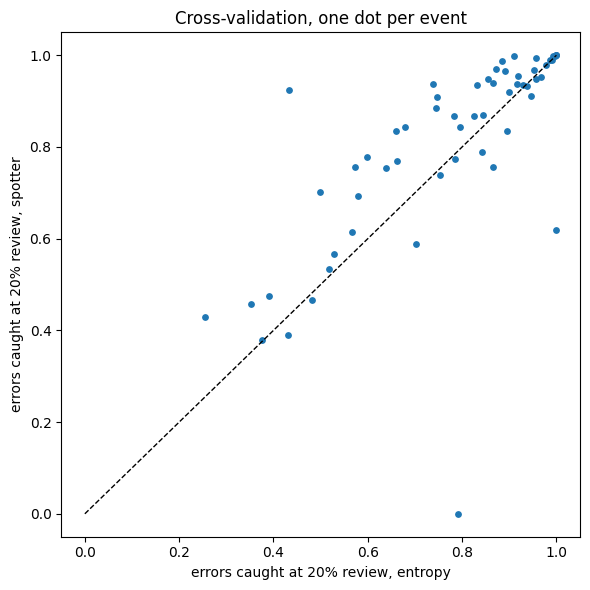

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(cv_table.entropy, cv_table.spotter, s=15)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("errors caught at 20% review, entropy")
ax.set_ylabel("errors caught at 20% review, spotter")
ax.set_title("Cross-validation, one dot per event")
plt.tight_layout()

When reviewing only top 20% of the cells, we catch 19% of the errors at random, 71% when ranked by predicted flood, 77% by models entropy and 81% with the spotter. Most of the errors sit where the model is unsure, so its uncertainity alone finds most of them.

## Holdout: 12 events, run once

The spotter is trained on all 60 spotter events and applied to the holdout. Results are given with and
without the September 2024 storm events (holdout_storm2024).

In [12]:
final = sp.fit_spotter(spot)
ho = sp.add_baseline_scores(hold)
ho["spotter"] = final.predict(ho[sp.FEATURES])

ho_scores = pd.concat({r: sp.capture(ho, r).set_index(["group", "event"]).captured for r in RANKINGS}, axis=1)
ho_scores.to_csv(f"{OUT_DIR}/holdout_capture_per_event.csv")
main = ho_scores.xs("holdout_main", level="group")
summary = pd.DataFrame({"all holdout events": ho_scores.mean(), "without Sept 2024 storm": main.mean()}).T
print(summary.round(3))
for name, t in [("all", ho_scores), ("without storm", main)]:
    d, lo, hi = sp.paired_bootstrap(t.spotter, t.entropy)
    print(f"{name:14s} spotter minus entropy {d:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  "
          f"better in {(t.spotter > t.entropy).sum()}/{len(t)} events")
ho_scores.round(3)

                         random  flood_fraction  entropy  spotter  oracle
all holdout events        0.186           0.681    0.789    0.837   0.947
without Sept 2024 storm   0.211           0.620    0.750    0.839   0.929
all            spotter minus entropy +0.048  95% CI [-0.056, +0.128]  better in 8/12 events
without storm  spotter minus entropy +0.089  95% CI [+0.031, +0.154]  better in 6/9 events


random  flood_fraction  entropy  spotter  oracle
group             event                                                    
holdout_main      EMSR251   0.100           0.525    0.977    0.967   1.000
                  EMSR321   0.196           0.790    0.759    0.914   0.984
                  EMSR358   0.147           0.755    0.958    0.937   1.000
                  EMSR556   0.168           0.656    0.781    0.870   1.000
                  EMSR841   0.286           0.714    0.714    1.000   1.000
                  EMSR844   0.333           0.607    0.787    0.905   0.974
                  EMSR845   0.235           0.392    0.436    0.577   0.721
                  EMSR860   0.189           0.816    0.961    0.943   1.000
                  EMSR867   0.246           0.321    0.376    0.436   0.683
holdout_storm2024 EMSR757   0.142           0.820    0.875    0.996   1.000
                  EMSR763   0.188           0.777    0.929    0.502   1.000
                  EMSR766   0.000           1.000    0.915    1.000   1.000

On the 12 holdout events, the spotter catches about 84% of errors and entropy of 79%. That is a slight gain. Without the storm events the gain is larger and clear, but on storm event EMSR763 the spotter does much worse (50% vs 93%). On EMSR867 and ESMR845, the map is wrong for over more than 20% of the area, so even a perfect ranking catches only about 70% of the errors.

## What the spotter relies on

Permutation importance on fold 0 of the cross-validation (spotter trained on folds 1 to 4): how much
worse its predictions get when one feature is shuffled.

In [13]:
from sklearn.inspection import permutation_importance

train, test = cv[cv.fold != 0], cv[(cv.fold == 0) & (cv.valid > 0)]
m0 = sp.fit_spotter(train)
sample = test.sample(min(50000, len(test)), random_state=0)
imp = permutation_importance(m0, sample[sp.FEATURES], sample.errors / sample.valid,
                             sample_weight=sample.valid, n_repeats=3, random_state=0)
pd.Series(imp.importances_mean, index=sp.FEATURES).sort_values(ascending=False).round(4)

,0
p_flood_mean,0.7000
vh_post_mean,0.2065
pred_flood_frac,0.1281
vv_post_mean,0.1016
dvv_below_m3,0.0208
p_flood_std,0.0208
entropy_mean,0.0186
dvv_mean,0.0145
patch_entropy_mean,0.0140
vv_post_std,0.0115


The spotter mostly uses the model's flood probability then VH radar. Terrain adds almost no value which make sense since the training flood are flat.

Reviewing 20% of the map, chosen by the model's uncertainty, catches about three quarters of its errors on floods it never saw (77% in cross-validation, 79% on the holdout), against 20% at random. The learned spotter adds a few points (81%, 84%), but not reliably. When the map is wrong over a large area (EMSR867, EMSR845), no 20% review is enough.